# PaySim feature store

In [1]:
from pathlib import Path
from datetime import timedelta
import json
import zipfile
import shutil
import tempfile
import sys
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from IPython.display import display
from feast import Entity, FeatureView, Field, FileSource, FeatureStore
from feast.repo_config import RepoConfig
from feast.types import Int64, Float64
from feast.value_type import ValueType

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (
    ROOT / 'feature_repo'
).exists(), 'Open the notebook from week8 or week8/notebooks'
RAW = ROOT / 'data/raw'
PROCESSED = ROOT / 'data/processed'
REPO = ROOT / 'feature_repo'
PROCESSED.mkdir(parents=True, exist_ok=True)
ORIGIN = pd.Timestamp('2025-01-01T00:00:00Z')
WINDOW_HOURS = 24
TTL_HOURS = 2
FEATURES = [
    'txn_count_24h',
    'amount_sum_24h',
    'amount_mean_24h',
    'transfer_count_24h',
    'has_history_24h',
]
FIELDS = FEATURES + ['snapshot_epoch_seconds', 'max_source_epoch_seconds']
FEATURE_REFS = [f'customer_history:{name}' for name in FIELDS]
run_temp = tempfile.TemporaryDirectory(prefix='week8_')
run_directory = Path(run_temp.name)

## STEP 2 — Data quality
We checck the data file to search for problematic transactions. Zero transactions or duplicate transactions are not deleted, but reported.

We use DuckDB to check through the histories and save full histories for specific customers.

In [2]:
REBUILD_DATA = False
cache_files = ['transactions.parquet', 'data_audit.json', 'raw_schema.csv']
rebuild = REBUILD_DATA or not all((PROCESSED / name).exists() for name in cache_files)

We extract the CSV if it is not already there.

In [3]:
if rebuild:
    for path in [RAW, PROCESSED]:
        path.mkdir(parents=True, exist_ok=True)
    archives = sorted(RAW.glob('*.zip'))
    if not archives:
        raise FileNotFoundError('Place the PaySim ZIP in data/raw.')
    archive = archives[0]
    with zipfile.ZipFile(archive) as z:
        members = [m for m in z.infolist() if m.filename.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError('Expected exactly one CSV in the downloaded ZIP.')
        member = members[0]
        csv_path = RAW / Path(member.filename).name
        if not csv_path.exists() or csv_path.stat().st_size != member.file_size:
            with z.open(member) as source, csv_path.open('wb') as target:
                import shutil

                shutil.copyfileobj(source, target)

We check the full CSV without loading it all into pandas.

In [4]:
if rebuild:
    con = duckdb.connect()
    con.execute("SET memory_limit='512MB'")
    con.execute('SET threads=2')
    con.execute('SET preserve_insertion_order=true')
    con.execute(f"SET temp_directory='{PROCESSED / 'duckdb_spill'}'")
    path = str(csv_path).replace("'", "''")
    con.execute(
        f"CREATE VIEW raw AS SELECT row_number() OVER () AS source_row_id, * FROM read_csv('{path}', header=true)"
    )
    schema = con.execute('DESCRIBE raw').df()
    expected = {'step', 'type', 'amount', 'nameOrig', 'nameDest', 'isFraud'}
    assert expected <= set(schema.column_name), 'Missing source columns'
    audit = (
        con.execute(
            """SELECT count(*) AS rows, min(step) AS min_step,max(step) AS max_step,
       count(*) FILTER(WHERE step IS NULL OR step<1 OR step!=floor(step)) AS invalid_steps,
       count(*) FILTER(WHERE nameOrig IS NULL OR trim(nameOrig)='') AS missing_sender,
       count(*) FILTER(WHERE nameDest IS NULL OR trim(nameDest)='') AS missing_recipient,
       count(*) FILTER(WHERE amount IS NULL OR NOT isfinite(amount)) AS invalid_amounts,
       count(*) FILTER(WHERE amount<0) AS negative_amounts,
       count(*) FILTER(WHERE amount=0) AS zero_amounts,
       count(*) FILTER(WHERE type IS NULL OR trim(type)='') AS missing_type,
       count(*) FILTER(WHERE isFraud IS NULL OR isFraud NOT IN (0,1)) AS invalid_labels,
       sum(isFraud) AS fraud_rows FROM raw"""
        )
        .df()
        .iloc[0]
        .to_dict()
    )
    audit = {k: int(v) for k, v in audit.items()}
    print('Raw audit:', audit, flush=True)
    valid_condition = "step>=1 AND step=floor(step) AND nameOrig IS NOT NULL AND trim(nameOrig)!='' AND amount IS NOT NULL AND isfinite(amount) AND amount>=0 AND type IS NOT NULL AND trim(type)!=''"
    con.execute('CREATE VIEW valid AS SELECT * FROM raw WHERE ' + valid_condition)

Raw audit: {'rows': 6362620, 'min_step': 1, 'max_step': 743, 'invalid_steps': 0, 'missing_sender': 0, 'missing_recipient': 0, 'invalid_amounts': 0, 'negative_amounts': 0, 'zero_amounts': 16, 'missing_type': 0, 'invalid_labels': 0, 'fraud_rows': 8213}


We choose customers and keep all their transactions.

In [5]:
if rebuild:
    con.execute("""CREATE TEMP TABLE customer_stats AS SELECT nameOrig AS customer_id,
        count(*) AS transaction_count,count(DISTINCT step) AS distinct_hours,
        min(step) AS first_step,max(step) AS last_step FROM valid GROUP BY nameOrig""")
    stats = (
        con.execute("""SELECT count(*) AS customers,
       count(*) FILTER(WHERE transaction_count=1) AS single_transaction_customers,
       count(*) FILTER(WHERE transaction_count>1) AS repeat_customers,
       count(*) FILTER(WHERE distinct_hours>1) AS cross_hour_customers,
       max(transaction_count) AS max_transactions_per_customer FROM customer_stats""")
        .df()
        .iloc[0]
        .to_dict()
    )
    audit.update({k: int(v) for k, v in stats.items()})
    print('Customer history:', stats, flush=True)
    con.execute(
        f"CREATE TEMP TABLE random_ids AS SELECT * FROM customer_stats ORDER BY md5(customer_id || ':42') LIMIT {int(400)}"
    )
    con.execute(
        f"CREATE TEMP TABLE active_ids AS SELECT * FROM customer_stats WHERE distinct_hours>1 AND customer_id NOT IN (SELECT customer_id FROM random_ids) ORDER BY md5(customer_id || ':42') LIMIT {int(100)}"
    )
    chosen = con.execute(
        "SELECT *, 'random_customer' AS cohort FROM random_ids UNION ALL SELECT *, 'active_demo' AS cohort FROM active_ids"
    ).df()
    con.register('chosen', chosen)
    transactions = con.execute(
        """SELECT r.source_row_id, r.nameOrig AS customer_id,r.step,r.type,r.amount,r.nameDest,r.isFraud,c.cohort
       FROM valid r JOIN chosen c ON r.nameOrig=c.customer_id ORDER BY r.source_row_id"""
    ).df()

Customer history: {'customers': 6353307, 'single_transaction_customers': 6344009, 'repeat_customers': 9298, 'cross_hour_customers': 9251, 'max_transactions_per_customer': 3}


We check duplicates and save the selected transactions.

In [6]:
if rebuild:
    duplicate_count = con.execute(
        """SELECT coalesce(sum(n-1),0) FROM (SELECT step,type,amount,nameOrig,nameDest,isFraud,
       oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud,count(*) n FROM raw GROUP BY ALL HAVING count(*)>1)"""
    ).fetchone()[0]
    audit['identical_full_rows_beyond_first'] = int(duplicate_count)
    audit['retained_valid_rows'] = int(
        con.execute('SELECT count(*) FROM valid').fetchone()[0]
    )
    audit['selected_rows'] = len(transactions)
    audit['selected_customers'] = len(chosen)
    audit['random_customer_count'] = int(chosen.cohort.eq('random_customer').sum())
    audit['active_demo_customer_count'] = int(chosen.cohort.eq('active_demo').sum())
    audit['selected_fraud_rows'] = int(transactions.isFraud.eq(1).sum())
    transactions['event_timestamp'] = ORIGIN + pd.to_timedelta(
        transactions.step.astype('int64') - 1, unit='h'
    )
    transactions['source_row_id'] = transactions.source_row_id.astype(str).radd(
        'paysim:'
    )
    assert transactions.source_row_id.is_unique
    transactions.to_parquet(PROCESSED / 'transactions.parquet', index=False)
    con.close()
    (PROCESSED / 'data_audit.json').write_text(json.dumps(audit, indent=2))
    print(
        'Prepared',
        len(transactions),
        'transactions for',
        len(chosen),
        'customers.',
        flush=True,
    )
    schema.to_csv(PROCESSED / 'raw_schema.csv', index=False)

Prepared 600 transactions for 500 customers.


This preparation will be used in the future on real data.

In [7]:
audit = json.loads((PROCESSED / 'data_audit.json').read_text())
display(
    pd.Series(
        {k: v for k, v in audit.items() if isinstance(v, (int, float))}, name='value'
    ).to_frame()
)
display(pd.read_csv(PROCESSED / 'raw_schema.csv'))

,value
rows,6362620
min_step,1
max_step,743
invalid_steps,0
missing_sender,0
missing_recipient,0
invalid_amounts,0
negative_amounts,0
zero_amounts,16
missing_type,0


,column_name,column_type,null,key,default,extra
0,source_row_id,BIGINT,YES,NaN,NaN,NaN
1,step,BIGINT,YES,NaN,NaN,NaN
2,type,VARCHAR,YES,NaN,NaN,NaN
3,amount,DOUBLE,YES,NaN,NaN,NaN
4,nameOrig,VARCHAR,YES,NaN,NaN,NaN
5,oldbalanceOrg,DOUBLE,YES,NaN,NaN,NaN
6,newbalanceOrig,DOUBLE,YES,NaN,NaN,NaN
7,nameDest,VARCHAR,YES,NaN,NaN,NaN
8,oldbalanceDest,DOUBLE,YES,NaN,NaN,NaN
9,newbalanceDest,DOUBLE,YES,NaN,NaN,NaN


No missing IDs, corrupted amounts or labels were found.

## STEP 3 — Customer histories
We chose to save 400 random users and 100 users that are active for multiple hours

,source_row_id,customer_id,step,type,amount,nameDest,isFraud,cohort,event_timestamp
0,paysim:9660,C1514502817,7,PAYMENT,18106.63,M1983541978,0,random_customer,2025-01-01 06:00:00+00:00
1,paysim:17929,C1923245546,8,PAYMENT,3458.09,M1679859032,0,active_demo,2025-01-01 07:00:00+00:00
2,paysim:21792,C459340937,8,CASH_OUT,155475.77,C1185525558,0,random_customer,2025-01-01 07:00:00+00:00
3,paysim:21894,C718494879,8,PAYMENT,15621.64,M1259891861,0,random_customer,2025-01-01 07:00:00+00:00
4,paysim:24178,C1256102702,8,CASH_IN,568011.47,C1060563153,0,random_customer,2025-01-01 07:00:00+00:00


,transactions,customers,fraud_cases
cohort,,,
active_demo,200,100,0
random_customer,400,400,0


,percent_of_customers
One transaction,99.853651
Repeated transactions,0.146349


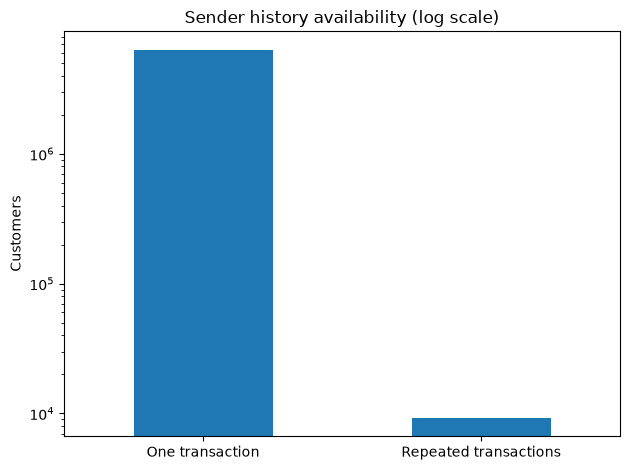

In [8]:
tx = pd.read_parquet(PROCESSED / 'transactions.parquet')
display(tx.head())
display(
    tx.groupby('cohort').agg(
        transactions=('customer_id', 'size'),
        customers=('customer_id', 'nunique'),
        fraud_cases=('isFraud', 'sum'),
    )
)
sparsity = pd.Series(
    {
        'One transaction': audit['single_transaction_customers'],
        'Repeated transactions': audit['repeat_customers'],
    }
)
display((100 * sparsity / audit['customers']).rename('percent_of_customers').to_frame())
sparsity.plot.bar(
    logy=True,
    title='Sender history availability (log scale)',
    ylabel='Customers',
    rot=0,
)
plt.tight_layout()
plt.show()

## STEP 4 — Event time
For step 1, we take it as 00:00 and for other steps we go 1 hour for each

In [9]:
time_examples = pd.DataFrame({'step': [1, 2, 24, audit['max_step']]})
time_examples['event_timestamp'] = ORIGIN + pd.to_timedelta(
    time_examples.step - 1, unit='h'
)
display(time_examples)
assert tx.event_timestamp.equals(ORIGIN + pd.to_timedelta(tx.step - 1, unit='h'))

,step,event_timestamp
0,1,2025-01-01 00:00:00+00:00
1,2,2025-01-01 01:00:00+00:00
2,24,2025-01-01 23:00:00+00:00
3,743,2025-01-31 22:00:00+00:00


## STEP 5 — Feature contract

Calculate the histories and get statistics from there.

In [10]:
contract = pd.DataFrame(
    [
        ['txn_count_24h', 'Past transaction count', '0'],
        ['amount_sum_24h', 'Past amount total', '0'],
        [
            'amount_mean_24h',
            'Past average amount',
            '0 placeholder; inspect has_history',
        ],
        ['transfer_count_24h', 'Past TRANSFER count', '0'],
        ['has_history_24h', 'At least one event in the window', '0'],
        [
            'snapshot_epoch_seconds',
            'Snapshot boundary; freshness only',
            'Missing for unknown customer',
        ],
        [
            'max_source_epoch_seconds',
            'Latest source event; leakage audit only',
            '-1 for empty window',
        ],
    ],
    columns=['feature', 'purpose', 'empty_window'],
)
display(contract)

,feature,purpose,empty_window
0,txn_count_24h,Past transaction count,0
1,amount_sum_24h,Past amount total,0
2,amount_mean_24h,Past average amount,0 placeholder; inspect has_history
3,transfer_count_24h,Past TRANSFER count,0
4,has_history_24h,At least one event in the window,0
5,snapshot_epoch_seconds,Snapshot boundary; freshness only,Missing for unknown customer
6,max_source_epoch_seconds,Latest source event; leakage audit only,-1 for empty window


Some users have missing features, and other get 0 counts

## STEP 6 — Small example
We use a few transactions to check if the calculations are correct.

We check for missing IDs, invalid times and invalid amounts.

In [11]:
def validate_transactions(frame):
    required = {'customer_id', 'event_timestamp', 'amount', 'type'}
    if not required <= set(frame):
        raise ValueError(f'Missing columns: {required - set(frame)}')
    if (
        frame.customer_id.isna().any()
        or frame.customer_id.astype(str).str.strip().eq('').any()
    ):
        raise ValueError('Missing entity keys')
    ts = pd.to_datetime(frame.event_timestamp, utc=True)
    if ts.isna().any() or not ts.eq(ts.dt.floor('h')).all():
        raise ValueError('Expected valid UTC hourly event timestamps')
    amounts = pd.to_numeric(frame.amount, errors='coerce')
    if not np.isfinite(amounts).all() or amounts.lt(0).any():
        raise ValueError('Expected finite nonnegative amounts')
    if frame.type.isna().any():
        raise ValueError('Missing transaction type')

We group transactions by hour and calculate the totals for the last 24 hours.

In [12]:
def build_snapshots(transactions, end_boundary, lag_minutes=0):
    validate_transactions(transactions)
    end = pd.Timestamp(end_boundary)
    if end.tzinfo is None or end != end.floor('h'):
        raise ValueError('End time must be a full hour with a timezone')
    if lag_minutes < 0:
        raise ValueError('Delay cannot be negative')

    parts = []
    for customer, history in transactions.groupby('customer_id', sort=True):
        history = history.copy()
        history['event_timestamp'] = pd.to_datetime(
            history['event_timestamp'], utc=True
        )
        start = history['event_timestamp'].min()
        if start >= end:
            continue

        hours = pd.date_range(start, end - pd.Timedelta(hours=1), freq='h')
        history = history[history['event_timestamp'] < end]
        history['is_transfer'] = (history['type'] == 'TRANSFER').astype(int)
        hourly = (
            history.groupby('event_timestamp')
            .agg(
                count=('amount', 'size'),
                total=('amount', 'sum'),
                transfers=('is_transfer', 'sum'),
            )
            .reindex(hours, fill_value=0)
        )

        rolling = hourly.rolling(WINDOW_HOURS, min_periods=1).sum()
        count = rolling['count'].astype('int64')
        total = rolling['total'].where(count > 0, 0.0)
        mean = total.div(count.replace(0, np.nan)).fillna(0.0)
        boundaries = hours + pd.Timedelta(hours=1)
        available = boundaries + pd.Timedelta(minutes=lag_minutes)

        event_seconds = pd.Series(hours.astype('int64') // 10**9, index=hours)
        last_event = event_seconds.where(hourly['count'] > 0)
        latest = last_event.rolling(WINDOW_HOURS, min_periods=1).max().fillna(-1)

        part = pd.DataFrame(index=hours)
        part['customer_id'] = str(customer)
        part['event_timestamp'] = available
        part['snapshot_boundary'] = boundaries
        part['created_timestamp'] = available
        part['snapshot_epoch_seconds'] = boundaries.astype('int64') // 10**9
        part['max_source_epoch_seconds'] = latest.astype('int64')
        part['txn_count_24h'] = count
        part['amount_sum_24h'] = total
        part['amount_mean_24h'] = mean
        part['transfer_count_24h'] = rolling['transfers'].astype('int64')
        part['has_history_24h'] = (count > 0).astype('int64')
        parts.append(part.reset_index(drop=True))

    if not parts:
        raise ValueError('No transactions before the end time')
    result = pd.concat(parts, ignore_index=True)
    assert not result.duplicated(['customer_id', 'event_timestamp']).any()
    assert (result['max_source_epoch_seconds'] < result['snapshot_epoch_seconds']).all()
    return result

We calculate the same values directly from the transactions to check our results.

In [13]:
def reference_values(
    transactions, customer, query_time, end_boundary, lag_minutes=0, ttl_hours=TTL_HOURS
):
    """Independent brute-force oracle: derive the scheduled boundary, then filter raw rows."""
    query = pd.Timestamp(query_time)
    end = pd.Timestamp(end_boundary)
    group = transactions.loc[transactions.customer_id.eq(customer)]
    missing = {k: None for k in FIELDS}
    if group.empty:
        return missing
    boundary = min((query - pd.Timedelta(minutes=lag_minutes)).floor('h'), end)
    if boundary <= group.event_timestamp.min().floor('h'):
        return missing
    available = boundary + pd.Timedelta(minutes=lag_minutes)
    if query - available > pd.Timedelta(hours=ttl_hours):
        return missing
    history = group.loc[
        (group.event_timestamp >= boundary - pd.Timedelta(hours=WINDOW_HOURS))
        & (group.event_timestamp < boundary)
    ]
    count = len(history)
    return {
        'txn_count_24h': count,
        'amount_sum_24h': float(history.amount.sum()),
        'amount_mean_24h': float(history.amount.mean()) if count else 0.0,
        'transfer_count_24h': int(history.type.eq('TRANSFER').sum()),
        'has_history_24h': int(count > 0),
        'snapshot_epoch_seconds': int(boundary.timestamp()),
        'max_source_epoch_seconds': (
            int(history.event_timestamp.max().timestamp()) if count else -1
        ),
    }

In [14]:
def fixture():
    return pd.DataFrame(
        {
            'customer_id': ['A', 'A', 'A', 'B', 'C'],
            'event_timestamp': [
                ORIGIN + pd.Timedelta(hours=h) for h in [0, 1, 1, 2, 0]
            ],
            'amount': [100.0, 50.0, 25.0, 7.0, 0.0],
            'type': ['TRANSFER', 'CASH_OUT', 'PAYMENT', 'TRANSFER', 'PAYMENT'],
        }
    )

In [15]:
tiny = fixture()
display(tiny)
tiny_snapshots = build_snapshots(tiny, ORIGIN + pd.Timedelta(hours=30))
display(tiny_snapshots.loc[tiny_snapshots.customer_id.eq('A')].head(3))
assert (
    reference_values(
        tiny, 'A', ORIGIN + pd.Timedelta(hours=2), ORIGIN + pd.Timedelta(hours=30)
    )['amount_sum_24h']
    == 175
)

,customer_id,event_timestamp,amount,type
0,A,2025-01-01 00:00:00+00:00,100.0,TRANSFER
1,A,2025-01-01 01:00:00+00:00,50.0,CASH_OUT
2,A,2025-01-01 01:00:00+00:00,25.0,PAYMENT
3,B,2025-01-01 02:00:00+00:00,7.0,TRANSFER
4,C,2025-01-01 00:00:00+00:00,0.0,PAYMENT


,customer_id,event_timestamp,snapshot_boundary,created_timestamp,snapshot_epoch_seconds,max_source_epoch_seconds,txn_count_24h,amount_sum_24h,amount_mean_24h,transfer_count_24h,has_history_24h
0,A,2025-01-01 01:00:00+00:00,2025-01-01 01:00:00+00:00,2025-01-01 01:00:00+00:00,1735693200,1735689600,1,100.0,100.000000,1,1
1,A,2025-01-01 02:00:00+00:00,2025-01-01 02:00:00+00:00,2025-01-01 02:00:00+00:00,1735696800,1735693200,3,175.0,58.333333,1,1
2,A,2025-01-01 03:00:00+00:00,2025-01-01 03:00:00+00:00,2025-01-01 03:00:00+00:00,1735700400,1735693200,3,175.0,58.333333,1,1


## STEP 7 — Save the features
We calculate hourly features and save them in Parquet. When old transactions leave the 24-hour window, the counts return to zero.

In [16]:
end = tx.event_timestamp.max() + pd.Timedelta(hours=WINDOW_HOURS + 2)
snapshots = build_snapshots(tx, end)
snapshots.to_parquet(PROCESSED / 'customer_hourly.parquet', index=False)
pd.testing.assert_frame_equal(
    snapshots, pd.read_parquet(PROCESSED / 'customer_hourly.parquet')
)
end_boundary = snapshots.snapshot_boundary.max()
assert not snapshots.duplicated(['customer_id', 'event_timestamp']).any()
assert (snapshots.max_source_epoch_seconds < snapshots.snapshot_epoch_seconds).all()
display(
    pd.Series(
        {
            'transactions': len(tx),
            'snapshots': len(snapshots),
            'customers': snapshots.customer_id.nunique(),
            'last_boundary': str(end_boundary),
        }
    ).to_frame('value')
)
display(snapshots.sample(5, random_state=42))

,value
transactions,600
snapshots,253830
customers,500
last_boundary,2025-01-31 19:00:00+00:00


,customer_id,event_timestamp,snapshot_boundary,created_timestamp,snapshot_epoch_seconds,max_source_epoch_seconds,txn_count_24h,amount_sum_24h,amount_mean_24h,transfer_count_24h,has_history_24h
128708,C2030882848,2025-01-30 05:00:00+00:00,2025-01-30 05:00:00+00:00,2025-01-30 05:00:00+00:00,1738213200,-1,0,0.0,0.0,0,0
73016,C1563809745,2025-01-21 07:00:00+00:00,2025-01-21 07:00:00+00:00,2025-01-21 07:00:00+00:00,1737442800,-1,0,0.0,0.0,0,0
180088,C409320657,2025-01-28 01:00:00+00:00,2025-01-28 01:00:00+00:00,2025-01-28 01:00:00+00:00,1738026000,-1,0,0.0,0.0,0,0
9575,C1056377786,2025-01-15 18:00:00+00:00,2025-01-15 18:00:00+00:00,2025-01-15 18:00:00+00:00,1736964000,-1,0,0.0,0.0,0,0
44524,C1332981150,2025-01-23 02:00:00+00:00,2025-01-23 02:00:00+00:00,2025-01-23 02:00:00+00:00,1737597600,-1,0,0.0,0.0,0,0


## STEP 8 — Set up Feast
We tell Feast where the features are and which customer they belong to.

In [17]:
import subprocess

subprocess.run(
    [str(Path(sys.executable).parent / 'feast'), '-c', str(REPO), 'apply'], check=True
)
store = FeatureStore(repo_path=str(REPO))
display(pd.DataFrame({'feature_view': [v.name for v in store.list_feature_views()]}))
assert {f.name for f in store.get_feature_view('customer_history').features} == set(
    FIELDS
)

No project found in the repository. Using project name paysim_week8 defined in feature_store.yaml
Applying changes for project paysim_week8
No changes to registry
No changes to infrastructure


,feature_view
0,customer_history


## STEP 9 — Prediction requests
For each transaction, we save the customer ID, time and fraud label. The label is not used to calculate features.

In [18]:
requests = tx[
    ['source_row_id', 'customer_id', 'event_timestamp', 'isFraud', 'cohort']
].copy()
assert requests.source_row_id.is_unique
display(requests.head())

,source_row_id,customer_id,event_timestamp,isFraud,cohort
0,paysim:9660,C1514502817,2025-01-01 06:00:00+00:00,0,random_customer
1,paysim:17929,C1923245546,2025-01-01 07:00:00+00:00,0,active_demo
2,paysim:21792,C459340937,2025-01-01 07:00:00+00:00,0,random_customer
3,paysim:21894,C718494879,2025-01-01 07:00:00+00:00,0,random_customer
4,paysim:24178,C1256102702,2025-01-01 07:00:00+00:00,0,random_customer


## STEP 10 — Get past features
We get the features that were available before each transaction. Future transactions are not included.

We get features for each customer and time, then join them back to all the original rows. Rows without features are kept.

In [19]:
def historical(store, entity_df):
    keys = ['customer_id', 'event_timestamp']
    requests = entity_df.copy()
    if requests[keys].isna().any().any():
        raise ValueError('Missing entity/time in prediction request')
    requests['event_timestamp'] = pd.to_datetime(requests.event_timestamp, utc=True)
    unique = requests[keys].drop_duplicates().reset_index(drop=True)
    retrieved = store.get_historical_features(
        entity_df=unique, features=FEATURE_REFS
    ).to_df()
    assert not retrieved.duplicated(keys).any()
    result = requests.merge(
        retrieved[keys + FIELDS],
        on=keys,
        how='left',
        validate='many_to_one',
        sort=False,
    )
    assert len(result) == len(requests)
    return result

We check that the values match. We allow small rounding differences for amounts.

In [20]:
def assert_values(expected, actual, context=''):
    for key in FIELDS:
        a = expected[key]
        b = actual[key]
        if pd.isna(a):
            assert pd.isna(b), f'{context} {key}: expected missing, got {b}'
        elif key in ['amount_sum_24h', 'amount_mean_24h']:
            assert np.isclose(
                a, b, rtol=1e-09, atol=1e-06
            ), f'{context} {key}: {a} != {b}'
        else:
            assert a == b, f'{context} {key}: {a} != {b}'

In [21]:
training = historical(store, requests)
assert len(training) == len(tx)
for row in training.itertuples(index=False):
    expected = reference_values(tx, row.customer_id, row.event_timestamp, end_boundary)
    assert_values(expected, row._asdict(), row.source_row_id)
training.to_parquet(PROCESSED / 'training_data.parquet', index=False)
coverage = (
    training.assign(
        has_snapshot=training.txn_count_24h.notna(),
        nonempty_history=training.has_history_24h.eq(1),
    )
    .groupby('cohort')
    .agg(
        requests=('customer_id', 'size'),
        matched_snapshots=('has_snapshot', 'sum'),
        nonempty_history=('nonempty_history', 'sum'),
    )
)
display(coverage)
display(training.head())
print(f'Independent raw-history checks passed for all {len(training)} prediction rows.')

,requests,matched_snapshots,nonempty_history
cohort,,,
active_demo,200,100,12
random_customer,400,0,0


,source_row_id,customer_id,event_timestamp,isFraud,cohort,txn_count_24h,amount_sum_24h,amount_mean_24h,transfer_count_24h,has_history_24h,snapshot_epoch_seconds,max_source_epoch_seconds
0,paysim:9660,C1514502817,2025-01-01 06:00:00+00:00,0,random_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,paysim:17929,C1923245546,2025-01-01 07:00:00+00:00,0,active_demo,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,paysim:21792,C459340937,2025-01-01 07:00:00+00:00,0,random_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,paysim:21894,C718494879,2025-01-01 07:00:00+00:00,0,random_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,paysim:24178,C1256102702,2025-01-01 07:00:00+00:00,0,random_customer,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Independent raw-history checks passed for all 600 prediction rows.


## STEP 11 — Check the results
We check the time limits, missing customers and future transactions.

We create separate stores for these checks so previous runs do not affect the results.

In [22]:
def make_store(parquet_path, store_dir):
    directory = Path(store_dir).resolve()
    directory.mkdir(parents=True, exist_ok=True)
    config = RepoConfig(
        project='paysim_week8',
        provider='local',
        registry=str(directory / 'registry.db'),
        offline_store={'type': 'file'},
        online_store={'type': 'sqlite', 'path': str(directory / 'online.db')},
        entity_key_serialization_version=3,
    )
    store = FeatureStore(config=config)
    customer = Entity(
        name='customer', join_keys=['customer_id'], value_type=ValueType.STRING
    )
    source = FileSource(
        name='customer_hourly_parquet',
        path=str(Path(parquet_path).resolve()),
        timestamp_field='event_timestamp',
        created_timestamp_column='created_timestamp',
    )
    view = FeatureView(
        name='customer_history',
        entities=[customer],
        source=source,
        ttl=timedelta(hours=TTL_HOURS),
        online=True,
        schema=[
            Field(
                name=k,
                dtype=Float64 if k in ['amount_sum_24h', 'amount_mean_24h'] else Int64,
            )
            for k in FIELDS
        ],
    )
    store.apply([customer, view])
    return store

We get the latest features. Missing, old or future values are marked as unusable.

In [23]:
def online(store, customers):
    return pd.DataFrame(
        store.get_online_features(
            features=FEATURE_REFS,
            entity_rows=[{'customer_id': str(c)} for c in customers],
        ).to_dict()
    )


def checked_online(store, customers, as_of, lag_minutes=0):
    """SQLite TTL is not enforced on read; reject stale/missing/future snapshots explicitly."""
    frame = online(store, customers)
    seconds = pd.to_numeric(frame.snapshot_epoch_seconds, errors='coerce')
    available = pd.to_datetime(seconds, unit='s', utc=True) + pd.Timedelta(
        minutes=lag_minutes
    )
    age = (pd.Timestamp(as_of) - available).dt.total_seconds() / 3600
    frame['feature_age_hours'] = age
    frame['feature_status'] = 'fresh'
    frame.loc[age > TTL_HOURS, 'feature_status'] = 'stale'
    frame.loc[age < 0, 'feature_status'] = 'future'
    frame.loc[seconds.isna(), 'feature_status'] = 'missing'
    frame.loc[frame.feature_status.ne('fresh'), FIELDS] = None
    return frame

We compare the raw calculations with the offline and online values.

In [24]:
def compare_three_paths(store, transactions, customers, cutoff, end_boundary):
    requests = pd.DataFrame(
        {
            'customer_id': customers,
            'event_timestamp': cutoff,
            'request_id': np.arange(len(customers)),
        }
    )
    off = historical(store, requests).set_index('customer_id')
    served = checked_online(store, customers, cutoff).set_index('customer_id')
    rows = []
    for customer in customers:
        expected = reference_values(transactions, customer, cutoff, end_boundary)
        for key in FIELDS:
            a = expected[key]
            b = off.loc[customer, key]
            c = served.loc[customer, key]
            if pd.isna(a):
                good = pd.isna(b) and pd.isna(c)
            elif key in ['amount_sum_24h', 'amount_mean_24h']:
                good = bool(
                    np.isclose(a, b, rtol=1e-09, atol=1e-06)
                    and np.isclose(a, c, rtol=1e-09, atol=1e-06)
                )
            else:
                good = bool(a == b and a == c)
            rows.append(
                {
                    'customer_id': customer,
                    'cutoff': cutoff,
                    'feature': key,
                    'raw_reference': a,
                    'offline': b,
                    'online': c,
                    'matches': bool(good),
                }
            )
    report = pd.DataFrame(rows)
    assert report.matches.all(), report.loc[~report.matches].head().to_string()
    return report

We check a few answers by hand, including empty histories and unknown users.

In [25]:
directory = run_directory / 'fixtures'
directory = Path(directory)
directory.mkdir(parents=True, exist_ok=True)
test_tx = fixture()
test_end = ORIGIN + pd.Timedelta(hours=30)
test_snapshots = build_snapshots(test_tx, test_end)
test_path = directory / 'fixture.parquet'
test_snapshots.to_parquet(test_path, index=False)
test_store = make_store(test_path, directory / 'store')
test_results = []


def record(name, detail):
    test_results.append({'check': name, 'passed': True, 'detail': detail})


expected_cases = [
    ('A', 0, None, None),
    ('A', 1, 1, 100.0),
    ('A', 2, 3, 175.0),
    ('A', 24, 3, 175.0),
    ('A', 25, 2, 75.0),
    ('A', 26, 0, 0.0),
    ('C', 1, 1, 0.0),
    ('UNKNOWN', 2, None, None),
]
queries = pd.DataFrame(
    [
        {
            'customer_id': c,
            'event_timestamp': ORIGIN + pd.Timedelta(hours=h),
            'case_id': i,
            'isFraud': i % 2,
        }
        for i, (c, h, _, __) in enumerate(expected_cases)
    ]
)
out = historical(test_store, queries).set_index('case_id')
assert len(out) == len(queries) and out.index.is_unique
for i, (customer, h, count, total) in enumerate(expected_cases):
    query = ORIGIN + pd.Timedelta(hours=h)
    expected = reference_values(test_tx, customer, query, test_end)
    assert_values(expected, out.loc[i], f'fixture case {i}')
    assert out.loc[i, 'isFraud'] == i % 2
    if count is None:
        assert pd.isna(out.loc[i, 'txn_count_24h'])
    else:
        assert out.loc[i, 'txn_count_24h'] == count and np.isclose(
            out.loc[i, 'amount_sum_24h'], total
        )
record(
    'hand_checked_boundaries',
    'Before-first, exact start included, current-hour excluded, ties, zero amount, expired rolling window and unknown entity',
)

We check that two requests at the same time both stay in the result.

In [26]:
duplicated = pd.concat(
    [queries.iloc[[2]].assign(case_id=101), queries.iloc[[2]].assign(case_id=102)],
    ignore_index=True,
)
dup_out = historical(test_store, duplicated)
assert len(dup_out) == 2 and set(dup_out.case_id) == {101, 102}
record(
    'duplicate_prediction_timestamps',
    'Two transaction IDs at the same entity/hour survive retrieval',
)

We shuffle the transactions and check that the features stay the same.

In [27]:
shuffled = build_snapshots(test_tx.sample(frac=1, random_state=42), test_end)
pd.testing.assert_frame_equal(test_snapshots, shuffled)
record('input_order_invariance', 'Shuffling input cannot invent within-hour chronology')

We add a future transaction. Earlier features should not change.

In [28]:
mutated = pd.concat(
    [
        test_tx,
        pd.DataFrame(
            {
                'customer_id': ['A'],
                'event_timestamp': [ORIGIN + pd.Timedelta(hours=20)],
                'amount': [1000000000.0],
                'type': ['TRANSFER'],
            }
        ),
    ],
    ignore_index=True,
)
future = build_snapshots(mutated, test_end)
pd.testing.assert_frame_equal(
    test_snapshots.loc[
        test_snapshots.event_timestamp <= ORIGIN + pd.Timedelta(hours=20)
    ].reset_index(drop=True),
    future.loc[future.event_timestamp <= ORIGIN + pd.Timedelta(hours=20)].reset_index(
        drop=True
    ),
)
future_path = directory / 'mutated.parquet'
future.to_parquet(future_path, index=False)
future_store = make_store(future_path, directory / 'future_store')
early = queries.loc[queries.event_timestamp <= ORIGIN + pd.Timedelta(hours=2)]
a = historical(test_store, early).sort_values('case_id').reset_index(drop=True)
b = historical(future_store, early).sort_values('case_id').reset_index(drop=True)
pd.testing.assert_frame_equal(a, b)
record(
    'future_mutation',
    'Adding a billion-unit future transaction does not change earlier Feast training rows',
)

We add a ten-minute delay. The features should not be available before that time.

In [29]:
delayed = build_snapshots(test_tx, test_end, lag_minutes=10)
delayed_path = directory / 'delayed.parquet'
delayed.to_parquet(delayed_path, index=False)
delayed_store = make_store(delayed_path, directory / 'delayed_store')
delayed_queries = pd.DataFrame(
    {
        'customer_id': ['A'] * 3,
        'event_timestamp': [
            ORIGIN + pd.Timedelta(hours=1, minutes=m) for m in [0, 9, 10]
        ],
        'case_id': [0, 1, 2],
    }
)
delayed_out = historical(delayed_store, delayed_queries).set_index('case_id')
assert pd.isna(delayed_out.loc[0, 'txn_count_24h']) and pd.isna(
    delayed_out.loc[1, 'txn_count_24h']
)
assert delayed_out.loc[2, 'txn_count_24h'] == 1
record(
    'availability_delay',
    'Snapshot ending at 01:00 is unavailable before its declared 01:10 availability',
)

We check that features older than two hours are not used.

In [30]:
ttl_queries = pd.DataFrame(
    {
        'customer_id': ['A', 'A'],
        'event_timestamp': [
            test_end + pd.Timedelta(hours=2),
            test_end + pd.Timedelta(hours=2, seconds=1),
        ],
    }
)
ttl_out = historical(test_store, ttl_queries).sort_values('event_timestamp')
assert pd.notna(ttl_out.iloc[0].txn_count_24h) and pd.isna(
    ttl_out.iloc[1].txn_count_24h
)
record(
    'historical_ttl_boundary',
    'Exactly two hours old accepted; older by one second missing',
)

We check whether Feast includes the exact end time when copying features.

In [31]:
exact = ORIGIN + pd.Timedelta(hours=2)
test_store.materialize(
    start_date=ORIGIN.to_pydatetime(), end_date=exact.to_pydatetime()
)
exact_row = online(test_store, ['A']).iloc[0]
exact_boundary_seconds = int(exact.timestamp())
if exact_row.snapshot_epoch_seconds == exact_boundary_seconds:
    boundary_behavior = 'inclusive end'
elif exact_row.snapshot_epoch_seconds == int(
    (exact - pd.Timedelta(hours=1)).timestamp()
):
    boundary_behavior = 'exclusive end'
else:
    raise AssertionError('Unexpected materialization boundary behavior')
record(
    'materialization_boundary_probe',
    boundary_behavior + '; main experiments use half-hour cutoffs',
)

Materializing 1 feature views from 2025-01-01 00:00:00+00:00 to 2025-01-01 02:00:00+00:00 into the sqlite online store.

customer_history:


We compare the offline and online values for our small example.

In [32]:
test_cutoff = ORIGIN + pd.Timedelta(hours=2, minutes=30)
test_store.materialize(
    start_date=ORIGIN.to_pydatetime(), end_date=test_cutoff.to_pydatetime()
)
compare_three_paths(
    test_store, test_tx, ['A', 'B', 'C', 'UNKNOWN'], test_cutoff, test_end
)
record(
    'fixture_three_way_consistency',
    'Raw arithmetic, Feast offline and SQLite online agree including missing keys',
)

Materializing 1 feature views from 2025-01-01 00:00:00+00:00 to 2025-01-01 02:30:00+00:00 into the sqlite online store.

customer_history:


We check that old activity becomes zero and stale features are rejected.

In [33]:
test_later = ORIGIN + pd.Timedelta(hours=27, minutes=30)
test_store.materialize(
    start_date=test_cutoff.to_pydatetime(), end_date=test_later.to_pydatetime()
)
assert online(test_store, ['A']).iloc[0].txn_count_24h == 0
stale_time = test_later + pd.Timedelta(hours=3)
assert pd.notna(online(test_store, ['A']).iloc[0].txn_count_24h)
assert checked_online(test_store, ['A'], stale_time).iloc[0].feature_status == 'stale'
assert pd.isna(checked_online(test_store, ['A'], stale_time).iloc[0].txn_count_24h)
assert checked_online(test_store, ['A'], test_cutoff).iloc[0].feature_status == 'future'
record(
    'online_freshness_guard',
    'Raw SQLite retains stale values; serving wrapper rejects stale and future state',
)
result = pd.DataFrame(test_results)

Materializing 1 feature views from 2025-01-01 02:30:00+00:00 to 2025-01-02 03:30:00+00:00 into the sqlite online store.

customer_history:


In [34]:
checks = pd.DataFrame(test_results)
display(checks)

,check,passed,detail
0,hand_checked_boundaries,True,"Before-first, exact start included, current-ho..."
1,duplicate_prediction_timestamps,True,Two transaction IDs at the same entity/hour su...
2,input_order_invariance,True,Shuffling input cannot invent within-hour chro...
3,future_mutation,True,Adding a billion-unit future transaction does ...
4,availability_delay,True,Snapshot ending at 01:00 is unavailable before...
5,historical_ttl_boundary,True,Exactly two hours old accepted; older by one s...
6,materialization_boundary_probe,True,inclusive end; main experiments use half-hour ...
7,fixture_three_way_consistency,True,"Raw arithmetic, Feast offline and SQLite onlin..."
8,online_freshness_guard,True,Raw SQLite retains stale values; serving wrapp...


## STEP 12 — Load the online store
We copy the available features into SQLite and look up customers by their IDs.

In [35]:
demo_store = make_store(
    PROCESSED / 'customer_hourly.parquet', run_directory / 'real_store'
)
cutoff = tx.event_timestamp.sort_values().iloc[len(tx) // 2].floor('h') + pd.Timedelta(
    minutes=30
)
start = snapshots.event_timestamp.min() - pd.Timedelta(seconds=1)
demo_store.materialize(
    start_date=start.to_pydatetime(), end_date=cutoff.to_pydatetime()
)
ids = sorted(tx.customer_id.unique().tolist()) + ['UNKNOWN_CUSTOMER']
served = checked_online(demo_store, ids, cutoff)
display(served.groupby('feature_status').size().rename('customers').to_frame())
display(served.loc[served.txn_count_24h.gt(0)].head())

Materializing 1 feature views from 2025-01-01 06:59:59+00:00 to 2025-01-10 21:30:00+00:00 into the sqlite online store.

customer_history:


,customers
feature_status,
fresh,273
missing,228


,customer_id,transfer_count_24h,amount_sum_24h,txn_count_24h,amount_mean_24h,max_source_epoch_seconds,has_history_24h,snapshot_epoch_seconds,feature_age_hours,feature_status
30,C1099603495,0.0,74119.74,1.0,74119.74,1.736510e+09,1.0,1.736543e+09,0.5,fresh
36,C1128307315,0.0,697755.84,2.0,348877.92,1.736532e+09,1.0,1.736543e+09,0.5,fresh
48,C1160169686,0.0,215146.91,1.0,215146.91,1.736539e+09,1.0,1.736543e+09,0.5,fresh
52,C1173659533,0.0,319715.35,1.0,319715.35,1.736518e+09,1.0,1.736543e+09,0.5,fresh
54,C1179766733,0.0,296831.65,1.0,296831.65,1.736514e+09,1.0,1.736543e+09,0.5,fresh


## STEP 13 — Compare offline and online
We check that both stores return the same values as our raw calculations.

In [36]:
first_report = compare_three_paths(demo_store, tx, ids, cutoff, end_boundary)
display(
    first_report.groupby('feature').agg(
        comparisons=('matches', 'size'), matches=('matches', 'sum')
    )
)
assert first_report.matches.all()

,comparisons,matches
feature,,
amount_mean_24h,501,501
amount_sum_24h,501,501
has_history_24h,501,501
max_source_epoch_seconds,501,501
snapshot_epoch_seconds,501,501
transfer_count_24h,501,501
txn_count_24h,501,501


## STEP 14 — Update the features
We move the time forward and check that old transactions leave the window. We also check that repeating the update does not change the result.

In [37]:
later = end_boundary + pd.Timedelta(minutes=30)
demo_store.materialize(
    start_date=cutoff.to_pydatetime(), end_date=later.to_pydatetime()
)
second_report = compare_three_paths(demo_store, tx, ids, later, end_boundary)
before = online(demo_store, ids).sort_values('customer_id').reset_index(drop=True)
demo_store.materialize(
    start_date=cutoff.to_pydatetime(), end_date=later.to_pydatetime()
)
after = online(demo_store, ids).sort_values('customer_id').reset_index(drop=True)
pd.testing.assert_frame_equal(before, after)
assert after.loc[after.customer_id.ne('UNKNOWN_CUSTOMER'), 'txn_count_24h'].eq(0).all()
consistency = pd.concat([first_report, second_report], ignore_index=True)
freshness = checked_online(demo_store, ids, later)
display(freshness.groupby('feature_status').size().to_frame('customers'))
display(checked_online(demo_store, ids[:3], later + pd.Timedelta(hours=3)))
assert (
    checked_online(demo_store, ids[:3], later + pd.Timedelta(hours=3))
    .feature_status.eq('stale')
    .all()
)

Materializing 1 feature views from 2025-01-10 21:30:00+00:00 to 2025-01-31 19:30:00+00:00 into the sqlite online store.

customer_history:


Materializing 1 feature views from 2025-01-10 21:30:00+00:00 to 2025-01-31 19:30:00+00:00 into the sqlite online store.

customer_history:


,customers
feature_status,
fresh,500
missing,1


,customer_id,transfer_count_24h,amount_sum_24h,txn_count_24h,amount_mean_24h,max_source_epoch_seconds,has_history_24h,snapshot_epoch_seconds,feature_age_hours,feature_status
0,C1001064466,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5,stale
1,C1003248237,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5,stale
2,C100462393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.5,stale


## STEP 15 — Check the labels
Our sample has no fraud cases, so we cannot train a useful fraud model with it.

In [38]:
display(training.isFraud.value_counts().rename_axis('isFraud').to_frame('transactions'))
model_status = (
    'Skipped: selected sample contains only one label class.'
    if training.isFraud.nunique() < 2
    else 'Not trained: optional extension requires chronological split evaluation.'
)
print(model_status)
print('Model input candidates:', FEATURES)

,transactions
isFraud,
0,600


Skipped: selected sample contains only one label class.
Model input candidates: ['txn_count_24h', 'amount_sum_24h', 'amount_mean_24h', 'transfer_count_24h', 'has_history_24h']


## STEP 16 — Results
We show the final counts and check if any values did not match.

In [39]:
summary = pd.Series(
    {
        'Raw transactions': audit['rows'],
        'Selected customers': tx.customer_id.nunique(),
        'Selected transactions': len(tx),
        'Hourly snapshots': len(snapshots),
        'Prediction rows checked': len(training),
        'Boundary checks passed': int(checks.passed.sum()),
        'Three-path comparisons': len(consistency),
        'Mismatches': int((~consistency.matches).sum()),
        'Repeated materialization unchanged': before.equals(after),
        'Final known windows empty': bool(
            after.loc[after.customer_id.ne('UNKNOWN_CUSTOMER'), 'txn_count_24h']
            .eq(0)
            .all()
        ),
    },
    name='result',
)
display(summary.to_frame())
assert consistency.matches.all()
print(model_status)
run_temp.cleanup()

,result
Raw transactions,6362620
Selected customers,500
Selected transactions,600
Hourly snapshots,253830
Prediction rows checked,600
Boundary checks passed,9
Three-path comparisons,7014
Mismatches,0
Repeated materialization unchanged,True
Final known windows empty,True


Skipped: selected sample contains only one label class.
